In [1]:
import os
import zipfile
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

from tensorflow.keras.applications import (
    VGG16,
    ResNet50,
    EfficientNetB0
)

from tensorflow.keras.applications.vgg16 import preprocess_input as vgg_preprocess
from tensorflow.keras.applications.resnet50 import preprocess_input as resnet_preprocess

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.20.0


In [2]:
print("GPU Available:")

if tf.config.list_physical_devices('GPU'):
    print("GPU is available")
    print(tf.config.list_physical_devices('GPU'))
else:
    print("GPU is NOT available. Training will be slower.")

GPU Available:
GPU is available
[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [3]:
from google.colab import files

uploaded = files.upload()

Saving Dataset_7.zip to Dataset_7.zip


In [5]:
import zipfile
import os

zip_path = "Dataset_7.zip"
extract_path = "/content/dataset"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [6]:
DATASET_DIR = "/content/dataset/Pistachio_Image_Dataset/Pistachio_Image_Dataset"

print(os.listdir(DATASET_DIR))

['Kirmizi_Pistachio', 'Siirt_Pistachio', 'Pistachio_Image_Dataset_Request.txt']


In [9]:
classes = [
    d for d in os.listdir(DATASET_DIR)
    if os.path.isdir(os.path.join(DATASET_DIR, d))
]

for class_name in classes:

    class_path = os.path.join(DATASET_DIR, class_name)

    count = len([
        f for f in os.listdir(class_path)
        if f.lower().endswith(('.jpg', '.jpeg', '.png'))
    ])

    print(class_name, ":", count, "images")

Kirmizi_Pistachio : 1232 images
Siirt_Pistachio : 916 images


Classes: ['Kirmizi_Pistachio', 'Siirt_Pistachio']


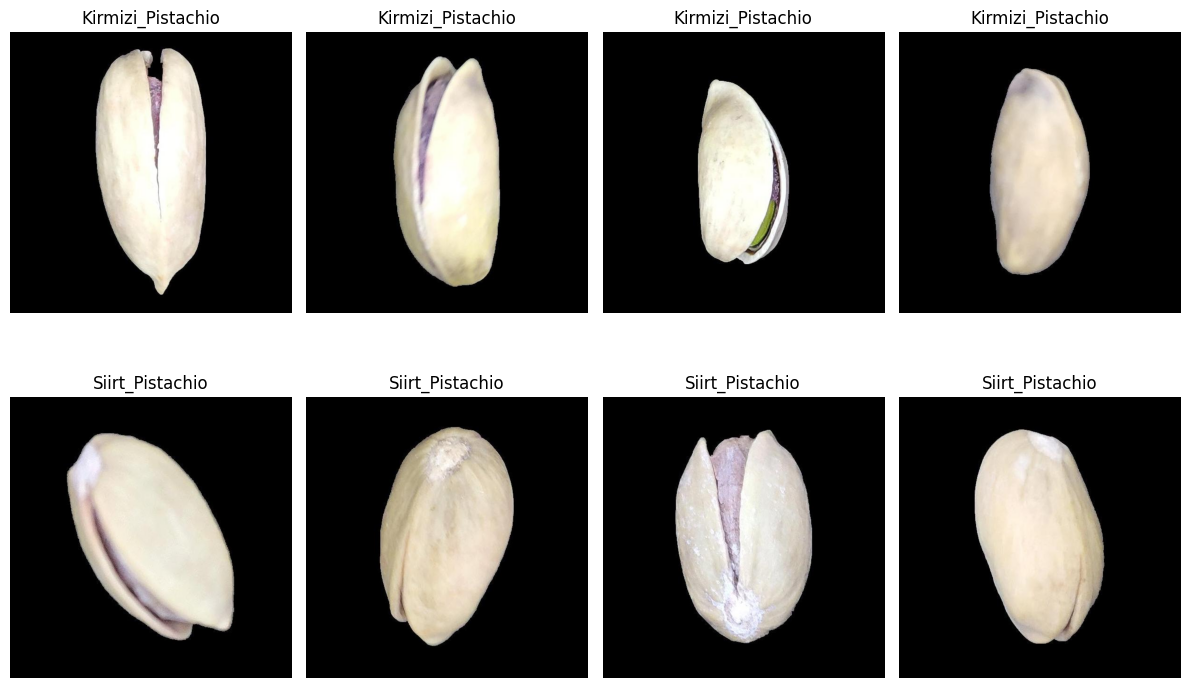

In [10]:
import random
import os
import matplotlib.pyplot as plt
from PIL import Image

# Only take directories as classes
classes = [
    d for d in os.listdir(DATASET_DIR)
    if os.path.isdir(os.path.join(DATASET_DIR, d))
]

print("Classes:", classes)

plt.figure(figsize=(12, 8))

plot_index = 1

for class_name in classes:

    class_path = os.path.join(DATASET_DIR, class_name)

    image_files = [
        f for f in os.listdir(class_path)
        if f.lower().endswith(('.jpg', '.jpeg', '.png'))
    ]

    # Display 4 random images from each class
    for j in range(min(4, len(image_files))):

        image_name = random.choice(image_files)
        image_path = os.path.join(class_path, image_name)

        image = Image.open(image_path)

        plt.subplot(len(classes), 4, plot_index)
        plt.imshow(image)
        plt.title(class_name)
        plt.axis("off")

        plot_index += 1

plt.tight_layout()
plt.show()

In [11]:
import os
import shutil
import random

SOURCE_DIR = DATASET_DIR
BASE_DIR = "/content/pistachio_split"

TRAIN_DIR = os.path.join(BASE_DIR, "train")
VAL_DIR = os.path.join(BASE_DIR, "validation")
TEST_DIR = os.path.join(BASE_DIR, "test")

# Remove previous split if it exists
if os.path.exists(BASE_DIR):
    shutil.rmtree(BASE_DIR)

for directory in [TRAIN_DIR, VAL_DIR, TEST_DIR]:
    os.makedirs(directory)

for class_name in classes:

    source_class = os.path.join(SOURCE_DIR, class_name)

    train_class = os.path.join(TRAIN_DIR, class_name)
    val_class = os.path.join(VAL_DIR, class_name)
    test_class = os.path.join(TEST_DIR, class_name)

    os.makedirs(train_class)
    os.makedirs(val_class)
    os.makedirs(test_class)

    images = [
        f for f in os.listdir(source_class)
        if f.lower().endswith(('.jpg', '.jpeg', '.png'))
    ]

    random.shuffle(images)

    total = len(images)

    train_end = int(0.70 * total)
    val_end = int(0.85 * total)

    train_images = images[:train_end]
    val_images = images[train_end:val_end]
    test_images = images[val_end:]

    for image in train_images:
        shutil.copy(
            os.path.join(source_class, image),
            os.path.join(train_class, image)
        )

    for image in val_images:
        shutil.copy(
            os.path.join(source_class, image),
            os.path.join(val_class, image)
        )

    for image in test_images:
        shutil.copy(
            os.path.join(source_class, image),
            os.path.join(test_class, image)
        )

print("Dataset split completed!")

Dataset split completed!


In [12]:
def count_images(directory):

    result = {}

    for class_name in classes:

        class_path = os.path.join(directory, class_name)

        result[class_name] = len([
            f for f in os.listdir(class_path)
            if f.lower().endswith(('.jpg', '.jpeg', '.png'))
        ])

    return result


print("Training:", count_images(TRAIN_DIR))
print("Validation:", count_images(VAL_DIR))
print("Testing:", count_images(TEST_DIR))

Training: {'Kirmizi_Pistachio': 862, 'Siirt_Pistachio': 641}
Validation: {'Kirmizi_Pistachio': 185, 'Siirt_Pistachio': 137}
Testing: {'Kirmizi_Pistachio': 185, 'Siirt_Pistachio': 138}


In [13]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
EPOCHS = 10

NUM_CLASSES = 2

print("Image size:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)
print("Epochs:", EPOCHS)

Image size: (224, 224)
Batch size: 32
Epochs: 10


In [14]:
train_datagen = ImageDataGenerator(
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode="nearest"
)

val_test_datagen = ImageDataGenerator()

In [15]:
train_generator = train_datagen.flow_from_directory(
    TRAIN_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="binary",
    shuffle=True
)

validation_generator = val_test_datagen.flow_from_directory(
    VAL_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="binary",
    shuffle=False
)

test_generator = val_test_datagen.flow_from_directory(
    TEST_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="binary",
    shuffle=False
)

print("Class indices:")
print(train_generator.class_indices)

Found 1503 images belonging to 2 classes.
Found 322 images belonging to 2 classes.
Found 323 images belonging to 2 classes.
Class indices:
{'Kirmizi_Pistachio': 0, 'Siirt_Pistachio': 1}


In [16]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.2,
    patience=2,
    min_lr=1e-7
)

In [17]:
def plot_history(history, model_name):

    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)

    plt.plot(history.history["accuracy"], label="Training Accuracy")
    plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

    plt.title(model_name + " Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()

    plt.subplot(1, 2, 2)

    plt.plot(history.history["loss"], label="Training Loss")
    plt.plot(history.history["val_loss"], label="Validation Loss")

    plt.title(model_name + " Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()

    plt.tight_layout()
    plt.show()

In [18]:
results = []

def evaluate_model(model, model_name):

    test_generator.reset()

    predictions = model.predict(test_generator)

    predicted_classes = (predictions > 0.5).astype(int).flatten()

    true_classes = test_generator.classes

    accuracy = accuracy_score(true_classes, predicted_classes)
    precision = precision_score(true_classes, predicted_classes)
    recall = recall_score(true_classes, predicted_classes)
    f1 = f1_score(true_classes, predicted_classes)

    results.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

    print("\n", "=" * 50)
    print(model_name)
    print("=" * 50)

    print("\nAccuracy :", accuracy)
    print("Precision:", precision)
    print("Recall   :", recall)
    print("F1 Score :", f1)

    print("\nClassification Report:\n")

    print(
        classification_report(
            true_classes,
            predicted_classes,
            target_names=list(test_generator.class_indices.keys())
        )
    )

    cm = confusion_matrix(true_classes, predicted_classes)

    plt.figure(figsize=(6, 5))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        xticklabels=test_generator.class_indices.keys(),
        yticklabels=test_generator.class_indices.keys()
    )

    plt.xlabel("Predicted Label")
    plt.ylabel("Actual Label")
    plt.title(model_name + " Confusion Matrix")

    plt.show()

In [19]:
def create_alexnet():

    model = models.Sequential([

        layers.Input(shape=(224, 224, 3)),

        # Block 1
        layers.Conv2D(96, (11, 11), strides=4, activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPooling2D(pool_size=(3, 3), strides=2),

        # Block 2
        layers.Conv2D(256, (5, 5), padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPooling2D(pool_size=(3, 3), strides=2),

        # Block 3
        layers.Conv2D(384, (3, 3), padding="same", activation="relu"),

        # Block 4
        layers.Conv2D(384, (3, 3), padding="same", activation="relu"),

        # Block 5
        layers.Conv2D(256, (3, 3), padding="same", activation="relu"),
        layers.MaxPooling2D(pool_size=(3, 3), strides=2),

        layers.Flatten(),

        layers.Dense(4096, activation="relu"),
        layers.Dropout(0.5),

        layers.Dense(4096, activation="relu"),
        layers.Dropout(0.5),

        layers.Dense(1, activation="sigmoid")
    ])

    return model

In [20]:
alexnet_model = create_alexnet()

alexnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

alexnet_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 54, 54, 96)     │        34,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 54, 54, 96)     │           384 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 26, 26, 96)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 26, 26, 256)    │       614,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 26, 26, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 12, 12, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 12, 12, 384)    │       885,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 12, 12, 384)    │     1,327,488 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 12, 12, 256)    │       884,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 5, 5, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6400)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4096)           │    26,218,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4096)           │    16,781,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │         4,097 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 46,752,513 (178.35 MB)

 Trainable params: 46,751,809 (178.34 MB)

 Non-trainable params: 704 (2.75 KB)

In [21]:
alexnet_history = alexnet_model.fit(
    train_generator,
    validation_data=validation_generator,
    epochs=EPOCHS,
    callbacks=[early_stopping, reduce_lr]
)

Epoch 1/10
47/47 ━━━━━━━━━━━━━━━━━━━━ 44s 677ms/step - accuracy: 0.5529 - loss: 0.8820 - val_accuracy: 0.6429 - val_loss: 0.6402 - learning_rate: 1.0000e-04
Epoch 2/10
47/47 ━━━━━━━━━━━━━━━━━━━━ 20s 430ms/step - accuracy: 0.6221 - loss: 0.6508 - val_accuracy: 0.4286 - val_loss: 1.1301 - learning_rate: 1.0000e-04
Epoch 3/10
47/47 ━━━━━━━━━━━━━━━━━━━━ 22s 467ms/step - accuracy: 0.6979 - loss: 0.5858 - val_accuracy: 0.7826 - val_loss: 0.5130 - learning_rate: 1.0000e-04
Epoch 4/10
47/47 ━━━━━━━━━━━━━━━━━━━━ 22s 474ms/step - accuracy: 0.6500 - loss: 0.6315 - val_accuracy: 0.7826 - val_loss: 0.4882 - learning_rate: 1.0000e-04
Epoch 5/10
47/47 ━━━━━━━━━━━━━━━━━━━━ 21s 446ms/step - accuracy: 0.7039 - loss: 0.5721 - val_accuracy: 0.8043 - val_loss: 0.4926 - learning_rate: 1.0000e-04
Epoch 6/10
47/47 ━━━━━━━━━━━━━━━━━━━━ 22s 460ms/step - accuracy: 0.6747 - loss: 0.6076 - val_accuracy: 0.7981 - val_loss: 0.4922 - learning_rate: 1.0000e-04
Epoch 7/10
47/47 ━━━━━━━━━━━━━━━━━━━━ 22s 463ms/step - acc

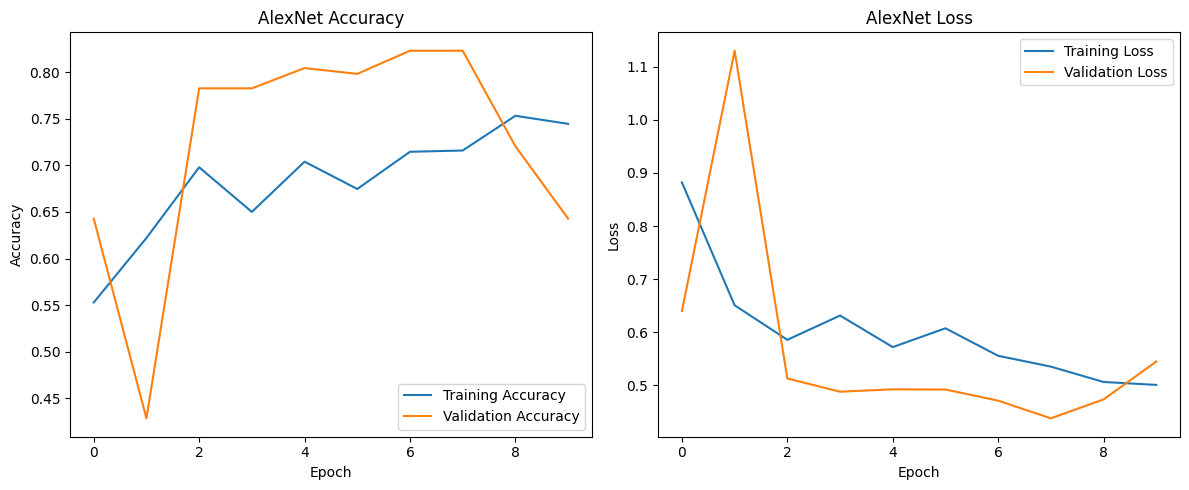

In [22]:
plot_history(alexnet_history, "AlexNet")

11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 227ms/step

AlexNet

Accuracy : 0.8235294117647058
Precision: 0.8584070796460177
Recall   : 0.7028985507246377
F1 Score : 0.7729083665338645

Classification Report:

                   precision    recall  f1-score   support

Kirmizi_Pistachio       0.80      0.91      0.86       185
  Siirt_Pistachio       0.86      0.70      0.77       138

         accuracy                           0.82       323
        macro avg       0.83      0.81      0.81       323
     weighted avg       0.83      0.82      0.82       323



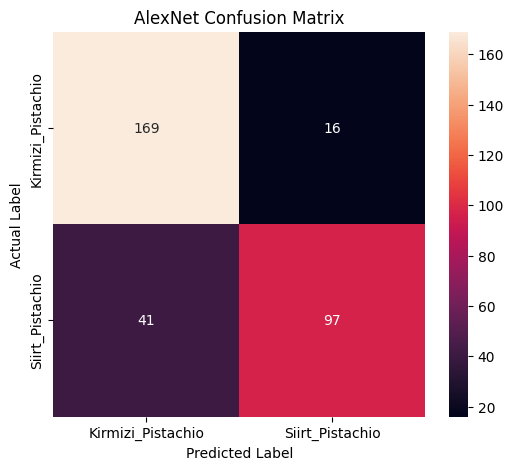

In [23]:
evaluate_model(
    alexnet_model,
    "AlexNet"
)

In [24]:
def create_vgg16():

    base_model = VGG16(
        weights="imagenet",
        include_top=False,
        input_shape=(224, 224, 3)
    )

    base_model.trainable = False

    model = models.Sequential([

        base_model,

        layers.GlobalAveragePooling2D(),

        layers.Dense(256, activation="relu"),
        layers.Dropout(0.5),

        layers.Dense(1, activation="sigmoid")
    ])

    return model

In [25]:
vgg16_model = create_vgg16()

vgg16_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

vgg16_model.summary()

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 7, 7, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,846,273 (56.63 MB)

 Trainable params: 131,585 (514.00 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [26]:
vgg16_history = vgg16_model.fit(
    train_generator,
    validation_data=validation_generator,
    epochs=EPOCHS,
    callbacks=[early_stopping, reduce_lr]
)

Epoch 1/10
47/47 ━━━━━━━━━━━━━━━━━━━━ 55s 848ms/step - accuracy: 0.5396 - loss: 1.6051 - val_accuracy: 0.7826 - val_loss: 0.5106 - learning_rate: 1.0000e-04
Epoch 2/10
47/47 ━━━━━━━━━━━━━━━━━━━━ 24s 508ms/step - accuracy: 0.6747 - loss: 0.9913 - val_accuracy: 0.8820 - val_loss: 0.3412 - learning_rate: 1.0000e-04
Epoch 3/10
47/47 ━━━━━━━━━━━━━━━━━━━━ 23s 491ms/step - accuracy: 0.7538 - loss: 0.7022 - val_accuracy: 0.9068 - val_loss: 0.2822 - learning_rate: 1.0000e-04
Epoch 4/10
47/47 ━━━━━━━━━━━━━━━━━━━━ 24s 507ms/step - accuracy: 0.7844 - loss: 0.5955 - val_accuracy: 0.9099 - val_loss: 0.2744 - learning_rate: 1.0000e-04
Epoch 5/10
47/47 ━━━━━━━━━━━━━━━━━━━━ 24s 510ms/step - accuracy: 0.7924 - loss: 0.5496 - val_accuracy: 0.8913 - val_loss: 0.3045 - learning_rate: 1.0000e-04
Epoch 6/10
47/47 ━━━━━━━━━━━━━━━━━━━━ 24s 513ms/step - accuracy: 0.8104 - loss: 0.5092 - val_accuracy: 0.9130 - val_loss: 0.2536 - learning_rate: 1.0000e-04
Epoch 7/10
47/47 ━━━━━━━━━━━━━━━━━━━━ 24s 511ms/step - acc

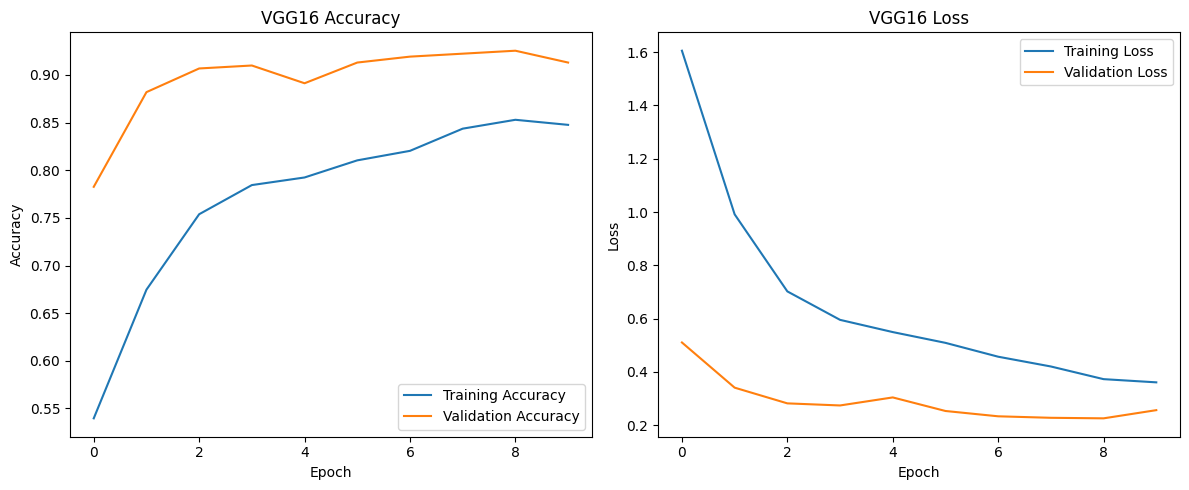

In [27]:
plot_history(vgg16_history, "VGG16")

11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 408ms/step

VGG16

Accuracy : 0.9102167182662538
Precision: 0.943089430894309
Recall   : 0.8405797101449275
F1 Score : 0.8888888888888888

Classification Report:

                   precision    recall  f1-score   support

Kirmizi_Pistachio       0.89      0.96      0.92       185
  Siirt_Pistachio       0.94      0.84      0.89       138

         accuracy                           0.91       323
        macro avg       0.92      0.90      0.91       323
     weighted avg       0.91      0.91      0.91       323



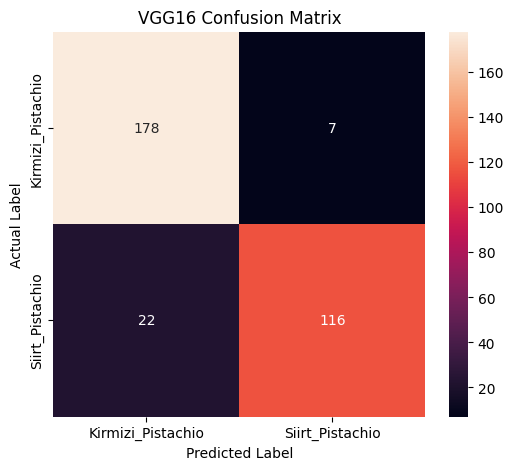

In [28]:
evaluate_model(
    vgg16_model,
    "VGG16"
)

In [29]:
def create_resnet50():

    base_model = ResNet50(
        weights="imagenet",
        include_top=False,
        input_shape=(224, 224, 3)
    )

    base_model.trainable = False

    model = models.Sequential([

        base_model,

        layers.GlobalAveragePooling2D(),

        layers.Dense(256, activation="relu"),
        layers.Dropout(0.5),

        layers.Dense(1, activation="sigmoid")
    ])

    return model

In [30]:
resnet50_model = create_resnet50()

resnet50_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

resnet50_model.summary()

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,112,513 (91.98 MB)

 Trainable params: 524,801 (2.00 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [31]:
resnet50_history = resnet50_model.fit(
    train_generator,
    validation_data=validation_generator,
    epochs=EPOCHS,
    callbacks=[early_stopping, reduce_lr]
)

Epoch 1/10
47/47 ━━━━━━━━━━━━━━━━━━━━ 47s 724ms/step - accuracy: 0.6401 - loss: 0.6740 - val_accuracy: 0.8261 - val_loss: 0.4419 - learning_rate: 1.0000e-04
Epoch 2/10
47/47 ━━━━━━━━━━━━━━━━━━━━ 21s 442ms/step - accuracy: 0.7738 - loss: 0.4765 - val_accuracy: 0.8634 - val_loss: 0.3547 - learning_rate: 1.0000e-04
Epoch 3/10
47/47 ━━━━━━━━━━━━━━━━━━━━ 23s 481ms/step - accuracy: 0.8077 - loss: 0.4266 - val_accuracy: 0.8634 - val_loss: 0.3425 - learning_rate: 2.0000e-05


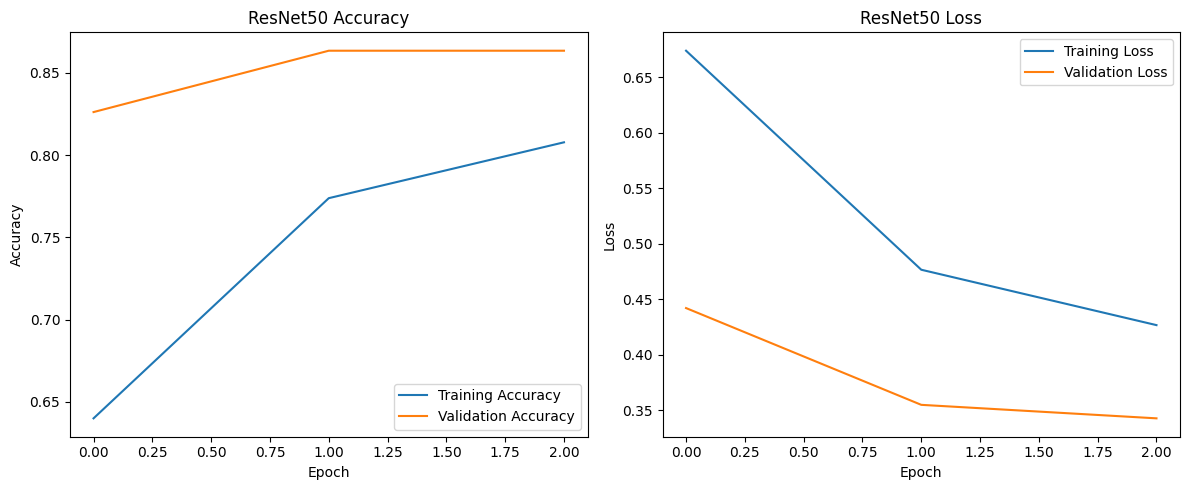

In [32]:
plot_history(resnet50_history, "ResNet50")

11/11 ━━━━━━━━━━━━━━━━━━━━ 10s 518ms/step

ResNet50

Accuracy : 0.8452012383900929
Precision: 0.8188405797101449
Recall   : 0.8188405797101449
F1 Score : 0.8188405797101449

Classification Report:

                   precision    recall  f1-score   support

Kirmizi_Pistachio       0.86      0.86      0.86       185
  Siirt_Pistachio       0.82      0.82      0.82       138

         accuracy                           0.85       323
        macro avg       0.84      0.84      0.84       323
     weighted avg       0.85      0.85      0.85       323



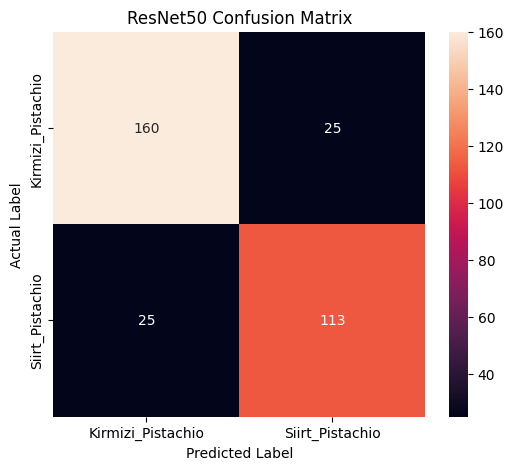

In [33]:
evaluate_model(
    resnet50_model,
    "ResNet50"
)

In [34]:
def create_efficientnet():

    base_model = EfficientNetB0(
        weights="imagenet",
        include_top=False,
        input_shape=(224, 224, 3)
    )

    base_model.trainable = False

    model = models.Sequential([

        base_model,

        layers.GlobalAveragePooling2D(),

        layers.Dense(256, activation="relu"),
        layers.Dropout(0.5),

        layers.Dense(1, activation="sigmoid")
    ])

    return model

In [35]:
efficientnet_model = create_efficientnet()

efficientnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

efficientnet_model.summary()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,377,764 (16.70 MB)

 Trainable params: 328,193 (1.25 MB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [36]:
efficientnet_history = efficientnet_model.fit(
    train_generator,
    validation_data=validation_generator,
    epochs=EPOCHS,
    callbacks=[early_stopping, reduce_lr]
)

Epoch 1/10
47/47 ━━━━━━━━━━━━━━━━━━━━ 83s 1s/step - accuracy: 0.7485 - loss: 0.5294 - val_accuracy: 0.8292 - val_loss: 0.4315 - learning_rate: 1.0000e-04
Epoch 2/10
47/47 ━━━━━━━━━━━━━━━━━━━━ 21s 441ms/step - accuracy: 0.8510 - loss: 0.3672 - val_accuracy: 0.8634 - val_loss: 0.3360 - learning_rate: 1.0000e-04
Epoch 3/10
47/47 ━━━━━━━━━━━━━━━━━━━━ 20s 422ms/step - accuracy: 0.8935 - loss: 0.3008 - val_accuracy: 0.8571 - val_loss: 0.3410 - learning_rate: 2.0000e-05


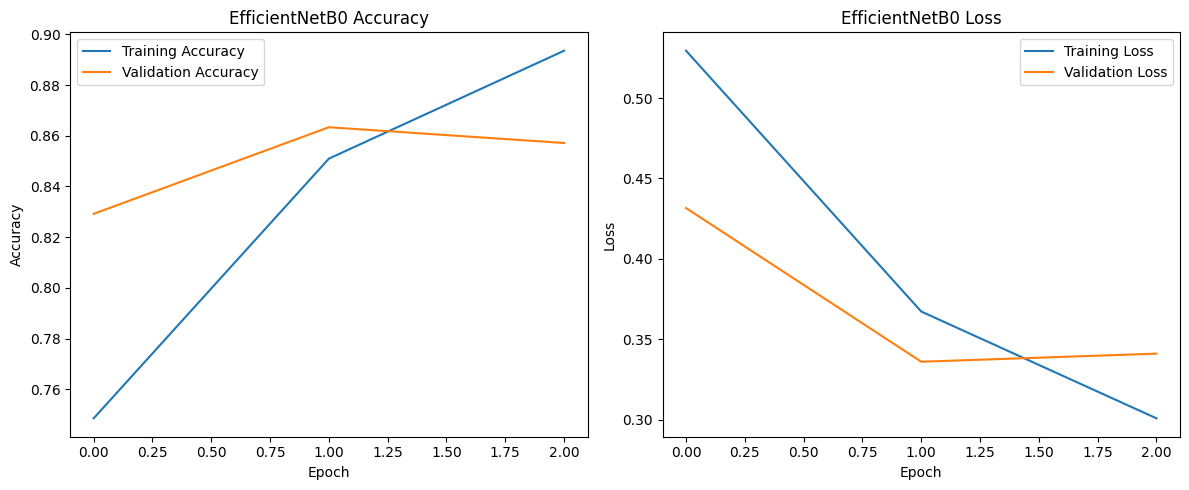

In [37]:
plot_history(
    efficientnet_history,
    "EfficientNetB0"
)

11/11 ━━━━━━━━━━━━━━━━━━━━ 20s 1s/step

EfficientNetB0

Accuracy : 0.8606811145510835
Precision: 0.7687861271676301
Recall   : 0.9637681159420289
F1 Score : 0.8553054662379421

Classification Report:

                   precision    recall  f1-score   support

Kirmizi_Pistachio       0.97      0.78      0.87       185
  Siirt_Pistachio       0.77      0.96      0.86       138

         accuracy                           0.86       323
        macro avg       0.87      0.87      0.86       323
     weighted avg       0.88      0.86      0.86       323



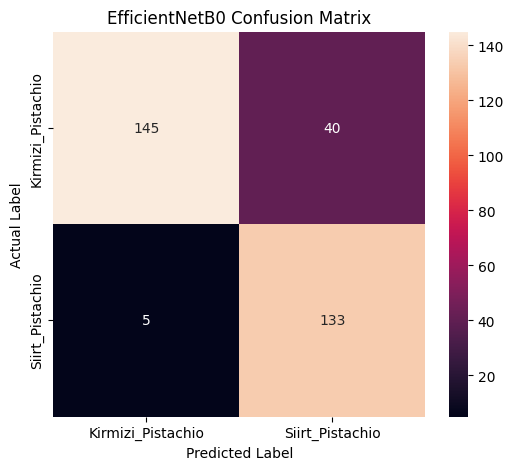

In [38]:
evaluate_model(
    efficientnet_model,
    "EfficientNetB0"
)

In [39]:
results_df = pd.DataFrame(results)

results_df

,Model,Accuracy,Precision,Recall,F1 Score
0,AlexNet,0.823529,0.858407,0.702899,0.772908
1,VGG16,0.910217,0.943089,0.840580,0.888889
2,ResNet50,0.845201,0.818841,0.818841,0.818841
3,EfficientNetB0,0.860681,0.768786,0.963768,0.855305


In [40]:
results_sorted = results_df.sort_values(
    by="Accuracy",
    ascending=False
)

results_sorted

,Model,Accuracy,Precision,Recall,F1 Score
1,VGG16,0.910217,0.943089,0.840580,0.888889
3,EfficientNetB0,0.860681,0.768786,0.963768,0.855305
2,ResNet50,0.845201,0.818841,0.818841,0.818841
0,AlexNet,0.823529,0.858407,0.702899,0.772908


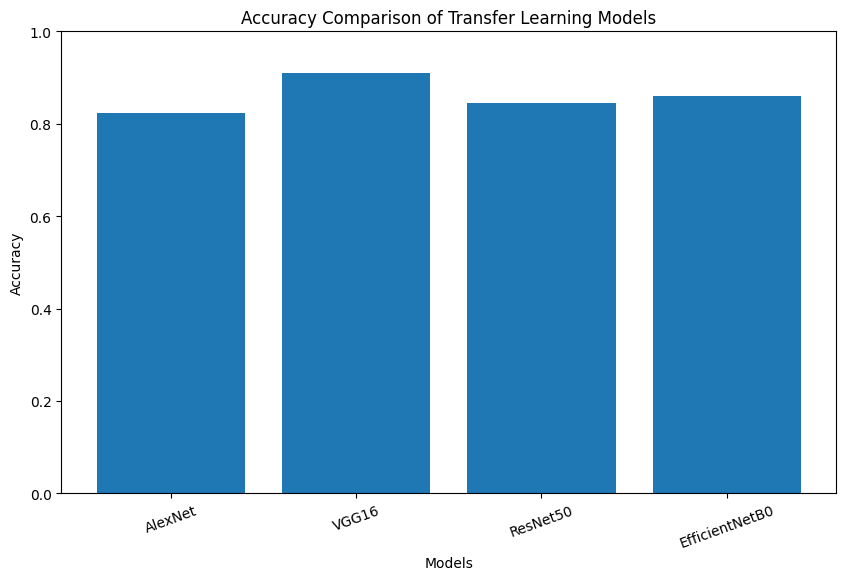

In [41]:
plt.figure(figsize=(10, 6))

plt.bar(
    results_df["Model"],
    results_df["Accuracy"]
)

plt.xlabel("Models")
plt.ylabel("Accuracy")
plt.title("Accuracy Comparison of Transfer Learning Models")

plt.ylim(0, 1)

plt.xticks(rotation=20)

plt.show()

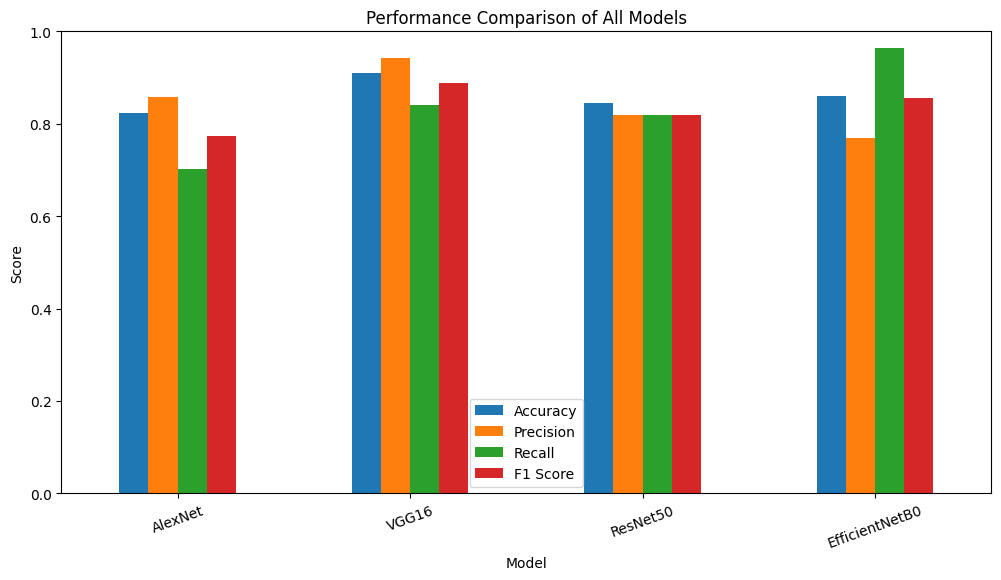

In [42]:
metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score"
]

results_plot = results_df.set_index("Model")[metrics]

results_plot.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Performance Comparison of All Models")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=20)

plt.legend()
plt.show()

In [43]:
best_model = results_df.loc[
    results_df["Accuracy"].idxmax()
]

print("Best Model:")
print(best_model["Model"])

print("\nAccuracy:", best_model["Accuracy"])
print("Precision:", best_model["Precision"])
print("Recall:", best_model["Recall"])
print("F1 Score:", best_model["F1 Score"])

Best Model:
VGG16

Accuracy: 0.9102167182662538
Precision: 0.943089430894309
Recall: 0.8405797101449275
F1 Score: 0.8888888888888888


In [44]:
results_df.to_csv(
    "/content/transfer_learning_results.csv",
    index=False
)

print("Results saved successfully!")

Results saved successfully!


In [45]:
alexnet_model.save("/content/alexnet_pistachio.keras")
vgg16_model.save("/content/vgg16_pistachio.keras")
resnet50_model.save("/content/resnet50_pistachio.keras")
efficientnet_model.save("/content/efficientnetb0_pistachio.keras")

print("All models saved successfully!")

All models saved successfully!
